## Testing which IC (Intrinsic Properties) respond to the treatment (FDR significant group X time)?


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# project PATH
DATASET_NAME = "sz_meditation"
project_path_str="/scratch/repo_"+DATASET_NAME
project_path= Path(project_path_str)
sys.path.append(str(project_path))

# importing private libs and functions (imaging_arsenal version, need to import the parent dir as well)
private_lib_path = Path('/scratch/imaging_arsenal')
sys.path.append(str(private_lib_path))
sys.path.append(str(private_lib_path / 'utils_'))
print('private lib ready:',(private_lib_path / 'utils_private.py').exists())
from utils_.utils_private import report_cpu
report_cpu()

# data path
data_path = project_path / 'data' 
fig_path = project_path / 'fig' 

# data
basic_time_Tag = "20240724"
all_DKT_path = data_path / (DATASET_NAME+'_R_'+basic_time_Tag+'.csv')
traj_data_path = data_path / "trajectory_class2_20240730.csv"

# read data
all_df = pd.read_csv(all_DKT_path, index_col= None)
tmp_df=all_df.copy()

private lib ready: False


/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Total CPUs: 12
Total Memory: 29.38 GB
Available Memory: 22.48 GB


In [2]:
# report major software version
import statsmodels 
import nilearn
import sys
import sklearn
import semopy
import seaborn as sns
import networkx as nx
import antropy
# setup random seed
rand_seed = 24
np.random.seed(rand_seed)

print('python version:', sys.version)
print('numpy version:', np.__version__)
print('statsmodels version:', statsmodels.__version__)
print('nilearn version:', nilearn.__version__)
print('sklearn version:', sklearn.__version__)
print('semopy version:', semopy.__version__)
print('networkX version:', nx.__version__)
print('seaborn version:', sns.__version__)
print('Antropy version:', antropy.__version__)
print('random seed:', rand_seed)

python version: 3.9.12 | packaged by conda-forge | (main, Mar 24 2022, 23:25:59) 
[GCC 10.3.0]
numpy version: 1.26.4
statsmodels version: 0.14.5
nilearn version: 0.12.0
sklearn version: 1.4.2
semopy version: 2.3.11
networkX version: 3.1
seaborn version: 0.13.2
Antropy version: 0.1.6
random seed: 24


In [3]:
# select clinical data out of full table (adding trajectory results)
test_cols = ['participant_id', 'group', 'age', 'session', 'CPZ_dose_0']
test_df = tmp_df[test_cols].copy()
test_df.rename(columns={'CPZ_dose_0': 'CPZ_dose'}, inplace=True)

# get participant index
test_df['patient_idx'], _ = pd.factorize(test_df['participant_id'])
# numerical adjustment
test_df['group'] = test_df['group'].astype('category')
test_df['session'] = test_df['session'].astype('category')
test_df.reset_index(drop=True, inplace=True)

test_df.head(3)

In [4]:
# Data preparation for mixed-effects model
from scipy.stats import zscore
import statsmodels.api as sm
import statsmodels.formula.api as smf

# read ICA results
ica_file_path = data_path / "IC_Stats_2026.csv"
ica_df = pd.read_csv(ica_file_path)

ica_sel_df = ica_df.copy()
ica_sel_df.drop(columns=['group', 'age'], inplace=True)
main_df = pd.merge(test_df, ica_sel_df, on=['participant_id', 'session'])

# zscore
main_df['mean_fd_z'] = zscore(main_df['mean_fd'], nan_policy='omit')
main_df['age_z'] = zscore(main_df['age'], nan_policy='omit')

# List of the 11 base network names from your dataframe
network_bases = [col.replace('_MeanZ', '') for col in ica_sel_df.columns if '_MeanZ' in col]

print('Data shape:', main_df.shape)
main_df.head(3)

Data shape: (167, 45)


## 1. Which IC respond to the treatment?

IC02 at 3 months.

To comprehensively map the neurobiological effects of the intervention, we evaluated network integrity across two primary theoretical domains: Spatial Cohesiveness (quantified by MeanZ, capturing intra-network topology and hub connectivity) and Intrinsic Temporal Complexity (quantified by Sample Entropy [SampEn], capturing the non-linear unpredictability of BOLD signal amplitude). To ensure the robustness of the temporal domain against signal-to-noise artifacts and fractal assumptions, Permutation Entropy (PermEn) and the Hurst Exponent (HE) were deployed as secondary sensitivity analyses.

In [5]:
## Prepare the data for mixed-effects model screening
import pandas as pd

# ==========================================
# 1. Isolate the Baseline Data (Session 0)
# ==========================================
base_df = main_df[main_df['session'] == 0].copy()

# Keep only the ID and the raw network metrics
base_cols = ['participant_id'] + [col for col in base_df.columns if any(net in col for net in network_bases)]
base_df = base_df[base_cols]

# Rename columns to explicitly mark them as baseline covariates
rename_dict = {col: f"{col}_base" for col in base_df.columns if col != 'participant_id'}
base_df = base_df.rename(columns=rename_dict)

# ==========================================
# 2. Isolate the Follow-up Data (Sessions 3 and 8)
# ==========================================
followup_df = main_df[main_df['session'].isin([3, 8])].copy()

# Fix: Explicitly cast 'session' as a categorical type before removing unused categories
followup_df['session'] = pd.Categorical(followup_df['session'], categories=[0, 3, 8], ordered=True)
followup_df['session'] = followup_df['session'].cat.remove_unused_categories()

# ==========================================
# 3. Merge Baseline Covariates into Follow-up Data
# ==========================================
model_df = pd.merge(followup_df, base_df, on='participant_id', how='inner')

print(f"Prepared dataframe shape: {model_df.shape}. Sessions included: {list(model_df['session'].unique())}")

Prepared dataframe shape: (99, 81). Sessions included: [3, 8]


In [6]:
import numpy as np
from scipy.stats import zscore
import statsmodels.formula.api as smf
import statsmodels.stats.multitest as mt

def run_baseline_adjusted_lmm(measure_name, df, networks):
    results = []
    
    # Standardize continuous covariates once
    df['age_z'] = zscore(df['age'].astype(float), nan_policy='omit')
    df['mean_fd_z'] = zscore(df['mean_fd'].astype(float), nan_policy='omit')
    
    for net in networks:
        target_col = f"{net}_{measure_name}"
        base_col = f"{target_col}_base"
        
        target_z_col = f"{target_col}_z"
        base_z_col = f"{base_col}_z"
        
        # Standardize the target metric AND its baseline equivalent
        df[target_z_col] = zscore(df[target_col].astype(float), nan_policy='omit')
        df[base_z_col] = zscore(df[base_col].astype(float), nan_policy='omit')
        
        # Model 1: Session 3 is the reference. The main group effect = Treatment effect at 3 months.
        formula_3 = f"{target_z_col} ~ C(group, Treatment('control')) * C(session, Treatment(3)) + {base_z_col} + age_z + mean_fd_z"
        
        # Model 2: Session 8 is the reference. The main group effect = Treatment effect at 8 months.
        formula_8 = f"{target_z_col} ~ C(group, Treatment('control')) * C(session, Treatment(8)) + {base_z_col} + age_z + mean_fd_z"
        
        try:
            # Fit both models
            model_3 = smf.mixedlm(formula_3, df, groups=df["participant_id"], missing='drop')
            fit_3 = model_3.fit(method=['powell', 'lbfgs'])
            
            model_8 = smf.mixedlm(formula_8, df, groups=df["participant_id"], missing='drop')
            fit_8 = model_8.fit(method=['powell', 'lbfgs'])
            
            # Extract the specific treatment effect at each time point
            term_group = "C(group, Treatment('control'))[T.meditation]"
            
            results.append({
                'Network': net,
                'Effect_Size_3mo': fit_3.params[term_group],
                'SE_3mo': fit_3.bse[term_group],
                't_val_3mo': fit_3.tvalues[term_group],
                'Raw_P_3mo': fit_3.pvalues[term_group],
                
                'Effect_Size_8mo': fit_8.params[term_group],
                'SE_8mo': fit_8.bse[term_group],
                't_val_8mo': fit_8.tvalues[term_group],
                'Raw_P_8mo': fit_8.pvalues[term_group],
                'Converged': fit_3.converged and fit_8.converged
            })
            
        except Exception as e:
            print(f"LMM failed for {net} {measure_name}: {e}")
            results.append({
                'Network': net,
                'Effect_Size_3mo': np.nan, 'SE_3mo': np.nan, 't_val_3mo': np.nan, 'Raw_P_3mo': np.nan,
                'Effect_Size_8mo': np.nan, 'SE_8mo': np.nan, 't_val_8mo': np.nan, 'Raw_P_8mo': np.nan,
                'Converged': False
            })
            
    res_df = pd.DataFrame(results)
    
    # Apply FDR correction
    valid_3mo = res_df['Raw_P_3mo'].dropna()
    valid_8mo = res_df['Raw_P_8mo'].dropna()
    
    res_df['FDR_Q_3mo'] = np.nan
    res_df['FDR_Q_8mo'] = np.nan
    
    if not valid_3mo.empty:
        _, qvals, _, _ = mt.multipletests(valid_3mo, method='fdr_bh')
        res_df.loc[valid_3mo.index, 'FDR_Q_3mo'] = qvals
        
    if not valid_8mo.empty:
        _, qvals, _, _ = mt.multipletests(valid_8mo, method='fdr_bh')
        res_df.loc[valid_8mo.index, 'FDR_Q_8mo'] = qvals
        
    cols = ['Network', 'Effect_Size_3mo', 'SE_3mo', 't_val_3mo', 'Raw_P_3mo', 'FDR_Q_3mo',
            'Effect_Size_8mo', 'SE_8mo', 't_val_8mo', 'Raw_P_8mo', 'FDR_Q_8mo', 'Converged']
    return res_df[cols]

# ==========================================
# 3. Execution Blocks
# ==========================================
# Make sure to pass 'model_df' (the newly prepped dataset), not 'main_df'

print("--- Spatial Cohesiveness (MeanZ) Results (Baseline Adjusted) ---")
meanz_res_adj = run_baseline_adjusted_lmm('MeanZ', model_df, network_bases)
display(meanz_res_adj)

print("\n--- Temporal Complexity (PermEn) Results (Baseline Adjusted) ---")
permen_res_adj = run_baseline_adjusted_lmm('PermEn', model_df, network_bases)
display(permen_res_adj)

print("\n--- Sample Entropy (SampEn) Results (Baseline Adjusted) ---")
sampen_res_adj = run_baseline_adjusted_lmm('SampEn', model_df, network_bases)
display(sampen_res_adj)

print("\n--- Fractal Dynamics (Hurst) Results (Baseline Adjusted) ---")
hurst_res_adj = run_baseline_adjusted_lmm('Hurst', model_df, network_bases)
display(hurst_res_adj)

--- Spatial Cohesiveness (MeanZ) Results (Baseline Adjusted) ---


,Network,Effect_Size_3mo,SE_3mo,t_val_3mo,Raw_P_3mo,FDR_Q_3mo,Effect_Size_8mo,SE_8mo,t_val_8mo,Raw_P_8mo,FDR_Q_8mo,Converged
0,IC00_SMN,0.128768,0.274619,0.468898,0.639143,0.821755,0.101580,0.293227,0.346421,0.729026,0.895395,True
1,IC02_SalVentA,-0.005327,0.230282,-0.023132,0.981545,0.981545,-0.032339,0.245964,-0.131480,0.895395,0.895395,True
2,IC04_Vis_V1,0.201308,0.250485,0.803670,0.421587,0.719300,0.039084,0.268592,0.145516,0.884304,0.895395,True
3,IC05_aDMN,0.603367,0.268206,2.249641,0.024472,0.150402,0.109097,0.287602,0.379333,0.704441,0.895395,True
4,IC09_pDMN,-0.518644,0.264774,-1.958819,0.050134,0.150402,-0.596207,0.280819,-2.123097,0.033746,0.303711,True
5,IC15_DAN,0.092452,0.273239,0.338354,0.735096,0.826983,0.149354,0.291781,0.511872,0.608740,0.895395,True
6,IC16_FPCN,-0.571098,0.282819,-2.019303,0.043456,0.150402,-0.377009,0.296621,-1.271011,0.203725,0.611175,True
7,IC18_SalVentB,-0.193837,0.274148,-0.707053,0.479533,0.719300,-0.221317,0.288607,-0.766848,0.443172,0.895395,True
8,IC19_ECN,-0.362344,0.270919,-1.337460,0.181073,0.407413,-0.414126,0.285781,-1.449103,0.147309,0.611175,True



--- Temporal Complexity (PermEn) Results (Baseline Adjusted) ---


,Network,Effect_Size_3mo,SE_3mo,t_val_3mo,Raw_P_3mo,FDR_Q_3mo,Effect_Size_8mo,SE_8mo,t_val_8mo,Raw_P_8mo,FDR_Q_8mo,Converged
0,IC00_SMN,0.460926,0.283670,1.624865,0.104191,0.528852,0.047213,0.298656,0.158083,0.874391,0.874391,True
1,IC02_SalVentA,-0.327628,0.286850,-1.142159,0.253388,0.528852,-0.072962,0.304021,-0.239989,0.810339,0.874391,True
2,IC04_Vis_V1,0.315429,0.279960,1.126695,0.259871,0.528852,0.334939,0.295366,1.133979,0.256804,0.577808,True
3,IC05_aDMN,0.305268,0.271508,1.124342,0.260868,0.528852,0.116243,0.288480,0.402951,0.686984,0.874391,True
4,IC09_pDMN,0.276926,0.263788,1.049807,0.293807,0.528852,0.159951,0.281459,0.568292,0.569837,0.874391,True
5,IC15_DAN,0.126040,0.266189,0.473500,0.635857,0.715339,0.427607,0.280442,1.524760,0.127319,0.572935,True
6,IC16_FPCN,0.231461,0.261990,0.883473,0.376981,0.565471,0.465326,0.280017,1.661780,0.096557,0.572935,True
7,IC18_SalVentB,0.021448,0.279809,0.076651,0.938901,0.938901,0.359148,0.299678,1.198448,0.230743,0.577808,True
8,IC19_ECN,0.215985,0.281844,0.766326,0.443483,0.570192,0.153505,0.301094,0.509823,0.610175,0.874391,True



--- Sample Entropy (SampEn) Results (Baseline Adjusted) ---


/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/opt/conda/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,Network,Effect_Size_3mo,SE_3mo,t_val_3mo,Raw_P_3mo,FDR_Q_3mo,Effect_Size_8mo,SE_8mo,t_val_8mo,Raw_P_8mo,FDR_Q_8mo,Converged
0,IC00_SMN,0.370755,0.278319,1.332122,0.182820,0.315475,0.624241,0.294774,2.117690,0.034201,0.183981,True
1,IC02_SalVentA,-0.095762,0.288885,-0.331487,0.740277,0.832811,0.052503,0.309692,0.169534,0.865376,0.865376,True
2,IC04_Vis_V1,0.451282,0.280323,1.609868,0.107427,0.297423,0.458964,0.299055,1.534713,0.124854,0.374563,True
3,IC05_aDMN,0.227277,0.271820,0.836132,0.403081,0.518246,0.113876,0.291822,0.390224,0.696371,0.865376,True
4,IC09_pDMN,0.347666,0.277534,1.252695,0.210317,0.315475,-0.282937,0.295049,-0.958951,0.337584,0.607650,True
5,IC15_DAN,0.404523,0.268692,1.505529,0.132188,0.297423,0.583320,0.285284,2.044698,0.040885,0.183981,True
6,IC16_FPCN,0.653780,0.277020,2.360047,0.018273,0.164454,0.069371,0.295764,0.234550,0.814558,0.865376,True
7,IC18_SalVentB,0.500075,0.278516,1.795500,0.072574,0.297423,0.386775,0.297244,1.301204,0.193189,0.434675,True
8,IC19_ECN,-0.029998,0.268435,-0.111753,0.911019,0.911019,-0.200773,0.287653,-0.697970,0.485196,0.727794,True



--- Fractal Dynamics (Hurst) Results (Baseline Adjusted) ---


,Network,Effect_Size_3mo,SE_3mo,t_val_3mo,Raw_P_3mo,FDR_Q_3mo,Effect_Size_8mo,SE_8mo,t_val_8mo,Raw_P_8mo,FDR_Q_8mo,Converged
0,IC00_SMN,-0.343217,0.281992,-1.217114,0.223561,0.350171,-0.209035,0.298179,-0.701040,0.483278,0.621358,True
1,IC02_SalVentA,0.397868,0.267353,1.488176,0.136704,0.350171,-0.218880,0.286030,-0.765234,0.444132,0.621358,True
2,IC04_Vis_V1,0.341303,0.251586,1.356606,0.174906,0.350171,-0.280416,0.269147,-1.041869,0.297473,0.621358,True
3,IC05_aDMN,0.065012,0.241676,0.269007,0.787924,0.787924,-0.222675,0.256021,-0.869752,0.384436,0.621358,True
4,IC09_pDMN,0.217443,0.259420,0.838191,0.401923,0.516758,-0.029905,0.276902,-0.107999,0.913996,0.927470,True
5,IC15_DAN,0.516996,0.251671,2.054248,0.039952,0.350171,-0.296331,0.267209,-1.108987,0.267436,0.621358,True
6,IC16_FPCN,0.280173,0.235138,1.191526,0.233447,0.350171,-0.022881,0.251366,-0.091028,0.927470,0.927470,True
7,IC18_SalVentB,0.101942,0.234817,0.434133,0.664192,0.747216,0.196440,0.252531,0.777883,0.436638,0.621358,True
8,IC19_ECN,0.311081,0.248326,1.252712,0.210311,0.350171,0.407676,0.265989,1.532680,0.125355,0.621358,True


In [7]:
# Combine all FDR columns from the 4 dataframes
all_q_values = pd.concat([
    meanz_res_adj[['FDR_Q_3mo', 'FDR_Q_8mo']],
    sampen_res_adj[['FDR_Q_3mo', 'FDR_Q_8mo']],
    permen_res_adj[['FDR_Q_3mo', 'FDR_Q_8mo']],
    hurst_res_adj[['FDR_Q_3mo', 'FDR_Q_8mo']]
])

# Get the absolute minimum across both 3mo and 8mo
min_q = all_q_values.min().min()
print(f"The absolute minimum FDR q-value across all local segregation tests is: {min_q:.3f}")

The absolute minimum FDR q-value across all local segregation tests is: 0.150


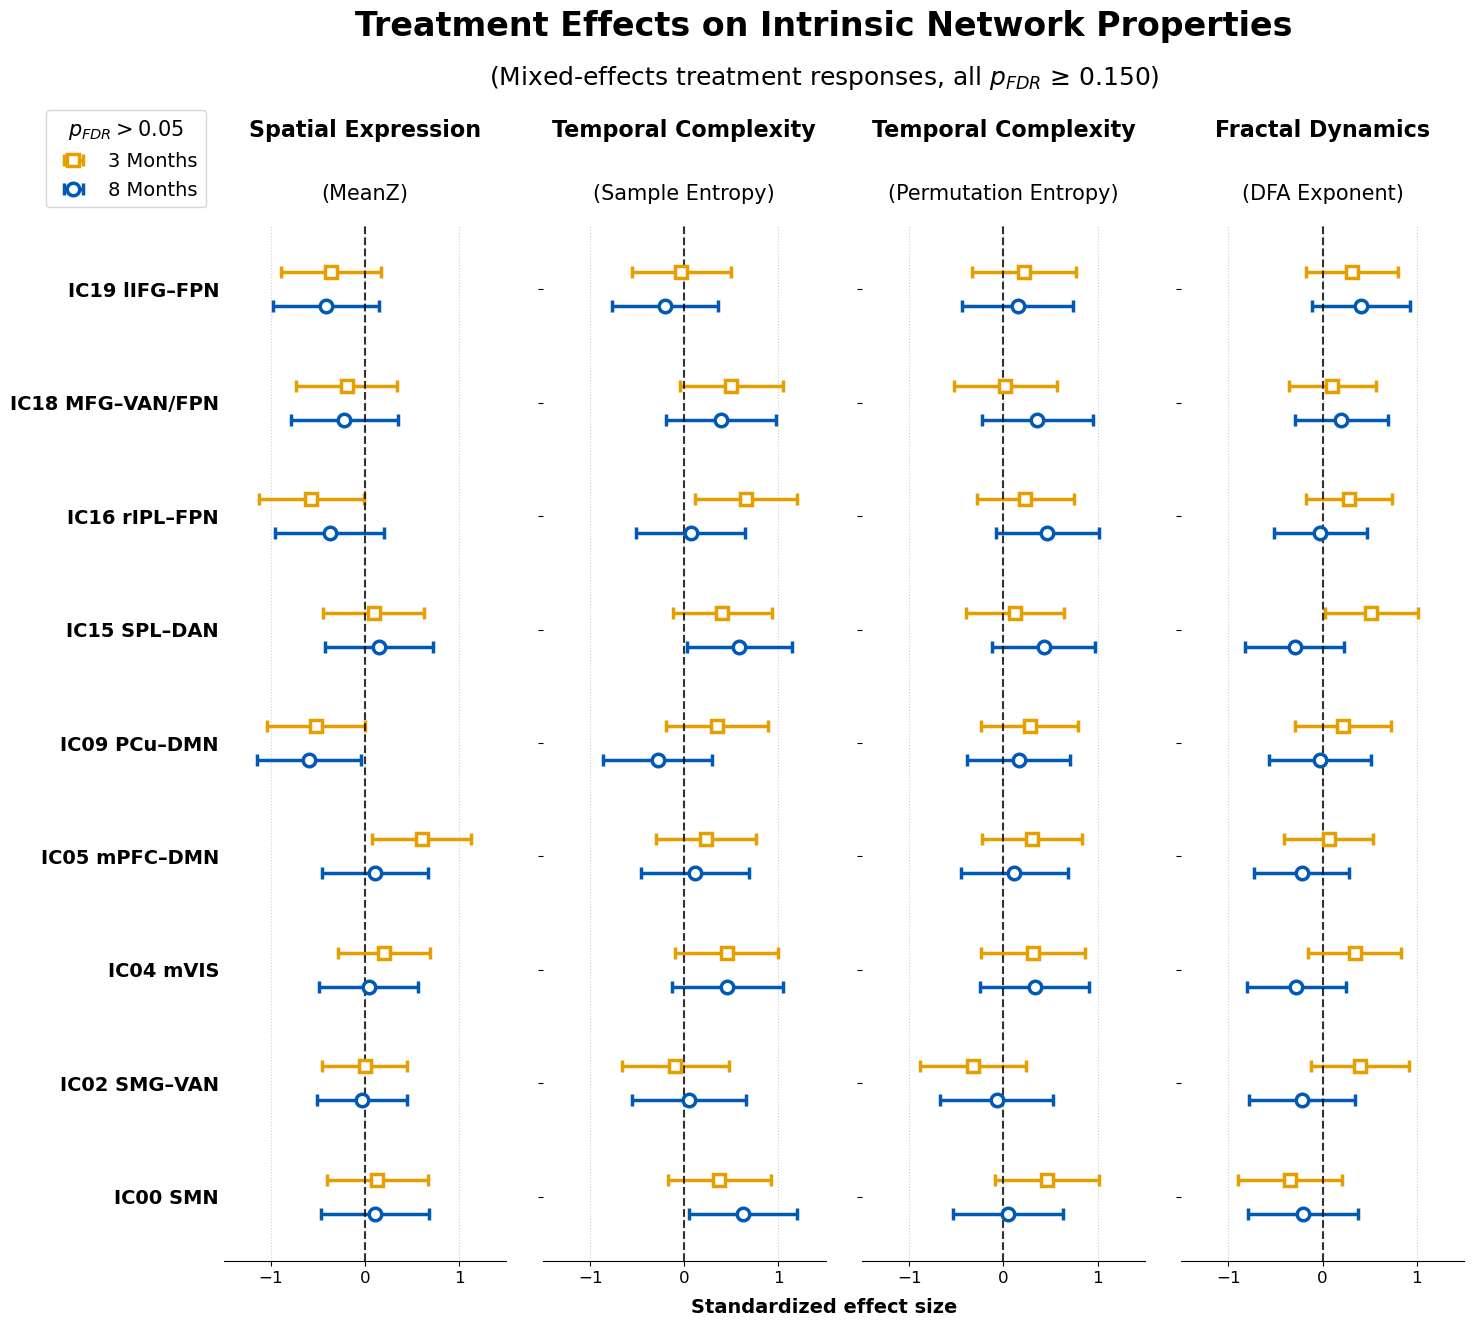

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

save_fig = 1
# 1. Define the data sources and updated metric titles
# Using a tuple for (Bold Title, Normal Subtitle)
metrics_data = {
    ('Spatial Expression', '(MeanZ)'): meanz_res_adj,
    ('Temporal Complexity', '(Sample Entropy)'): sampen_res_adj,
    ('Temporal Complexity', '(Permutation Entropy)'): permen_res_adj, 
    ('Fractal Dynamics', '(DFA Exponent)'): hurst_res_adj
}

network_name_mapping = {
    'IC00_SMN': 'SMN', 
    'IC02_SalVentA': 'SMG–VAN',
    'IC04_Vis_V1': 'mVIS', 
    'IC05_aDMN': 'mPFC–DMN',
    'IC09_pDMN': 'PCu–DMN', 
    'IC15_DAN': 'SPL–DAN',
    'IC16_FPCN': 'rIPL–FPN',
    'IC18_SalVentB': 'MFG–VAN/FPN',
    'IC19_ECN': 'lIFG–FPN',
}

for k,v in network_name_mapping.items():
   network_name_mapping[k]=k[0:4]+' '+v

# 3. Setup the figure
fig, axes = plt.subplots(1, 4, figsize=(16, 14), sharey=True)
plt.subplots_adjust(wspace=0.13, top=0.85) # Added top margin for titles

# Map the raw network names to the clean names
networks_raw = meanz_res_adj['Network'].tolist()
networks_clean = [network_name_mapping.get(net, net) for net in networks_raw]
y_positions = np.arange(len(networks_clean))

color_8mo = '#005AB5'  # Deep Royal Blue (Progressive Consolidation)
color_3mo = '#E69F00'  # Amber/Gold (Transient State)

# 4. Loop through each metric and plot
for ax, (titles, df) in zip(axes, metrics_data.items()):
    bold_title, normal_subtitle = titles
    
    # Calculate 95% Confidence Intervals (1.96 * SE)
    ci_3mo = df['SE_3mo'] * 1.96
    ci_8mo = df['SE_8mo'] * 1.96
    
    # Plot 8-month effects (slight negative offset on Y-axis)
    ax.errorbar(df['Effect_Size_8mo'], y_positions - 0.15, xerr=ci_8mo, 
                fmt='o', color=color_8mo, ecolor=color_8mo, elinewidth=2.5, capsize=4, 
                markersize=9, markerfacecolor='white', markeredgewidth=2.5, label='8 Months')
    
    # Plot 3-month effects (HOLLOW MARKERS: markerfacecolor='white')
    ax.errorbar(df['Effect_Size_3mo'], y_positions + 0.15, xerr=ci_3mo, 
                fmt='s', color=color_3mo, ecolor=color_3mo, elinewidth=2.5, capsize=4, 
                markersize=9, markerfacecolor='white', markeredgewidth=2.5, label='3 Months')

    # Formatting the subplot axes
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.8)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=12)
    ax.set_xlim(-1.5, 1.5)
    
    # Custom Dual-Weight Subtitles
    ax.text(0.5, 1.08, bold_title, ha='center', va='bottom', transform=ax.transAxes, 
            fontsize=16, fontweight='bold')
    ax.text(0.5, 1.02, normal_subtitle, ha='center', va='bottom', transform=ax.transAxes, 
            fontsize=15, fontweight='normal')
    
    # Despine and grid
    sns.despine(ax=ax, left=True)
    ax.grid(axis='x', linestyle=':', alpha=0.6)

# 5. Format the shared Y-axis with updated names
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(networks_clean, fontsize=14, fontweight='bold')
axes[0].tick_params(axis='y', length=0) # Hide tick marks, keep labels

# 6. Add legend to the first plot
handles, labels = axes[0].get_legend_handles_labels()
idx = [1, 0]  # swap them -> ['3 Months', '8 Months']
axes[0].legend([handles[i] for i in idx], [labels[i] for i in idx],
               title='$p_{FDR} > 0.05$', title_fontsize=15,
               loc='upper right', fontsize=14,
               bbox_to_anchor=(-0.03, 1.12), frameon=True, shadow=False)


# 7. Custom Dual-Weight Main Title
fig.text(0.5, 0.98, 'Treatment Effects on Intrinsic Network Properties', ha='center', va='bottom', 
         fontsize=24, fontweight='bold')
fig.text(0.5, 0.945, '(Mixed-effects treatment responses, all $p_{FDR}$'+f' ≥ {min_q:.3f})', 
         ha='center', va='bottom', fontsize=18, fontweight='normal')
#
fig.text(0.5, 0.07, 'Standardized effect size', 
         ha='center', va='bottom', fontsize=14, fontweight='bold')

plt.show()

if save_fig:
    fig.savefig(fig_path /'Figure3a_Local_Nulls_ForestPlot.png', dpi=300, bbox_inches='tight')